# MediaPipe Vision: From Landmarks to Vision Tasks

A practical tour of MediaPipe's Vision capabilities.

## 1. Setup


In [ ]:
import os
import urllib.request
from pathlib import Path
import subprocess
import shutil


import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.vision import drawing_utils, drawing_styles

print("MediaPipe version:", mp.__version__)

### Model files and sample assets

Download the required `.task` / `.tflite` models and a small set of images.
Place them under `models/` and `data/images/`.

In [ ]:

MODELS_DIR = Path("models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:

MODEL_URLS = {
    "holistic_landmarker.task":
        "https://storage.googleapis.com/mediapipe-models/holistic_landmarker/holistic_landmarker/float16/latest/holistic_landmarker.task",
    "blaze_face_short_range.tflite":
        "https://storage.googleapis.com/mediapipe-models/face_detector/blaze_face_short_range/float16/1/blaze_face_short_range.tflite",
    "gesture_recognizer.task":
        "https://storage.googleapis.com/mediapipe-models/gesture_recognizer/gesture_recognizer/float16/latest/gesture_recognizer.task",
    "efficientnet_lite0.tflite":
        "https://storage.googleapis.com/mediapipe-models/image_classifier/efficientnet_lite0/float32/latest/efficientnet_lite0.tflite",
    "efficientdet_lite0.tflite":
        "https://storage.googleapis.com/mediapipe-models/object_detector/efficientdet_lite0/float16/1/efficientdet_lite0.tflite",
    "selfie_segmenter.tflite":
        "https://storage.googleapis.com/mediapipe-models/image_segmenter/selfie_segmenter/float16/latest/selfie_segmenter.tflite",
    "magic_touch.tflite":
        "https://storage.googleapis.com/mediapipe-models/interactive_segmenter/magic_touch/float32/1/magic_touch.tflite",
}

def download_file(url: str, dest: Path):
    if dest.exists() and dest.stat().st_size > 1000:
        print(f"Already present: {dest.name} ({dest.stat().st_size // 1024} KB)")
        return

    print(f"Downloading {dest.name} ...")
    # Prefer curl if available (better with GCS)
    if shutil.which("curl"):
        cmd = [
            "curl", "-L", "--fail", "--retry", "3",
            "-A", "Mozilla/5.0 (compatible; MediaPipeCourse/1.0)",
            "-o", str(dest), url
        ]
        subprocess.check_call(cmd)
    else:
        req = urllib.request.Request(
            url,
            headers={"User-Agent": "Mozilla/5.0 (compatible; MediaPipeCourse/1.0)"},
        )
        with urllib.request.urlopen(req, timeout=180) as r:
            dest.write_bytes(r.read())
    print(f"  -> saved to {dest} ({dest.stat().st_size // 1024} KB)")

for name, url in MODEL_URLS.items():
    try:
        download_file(url, MODELS_DIR / name)
    except Exception as e:
        print(f"FAILED {name}: {e}")

print("\nModels ready.")

In [ ]:

IMAGES_DIR = Path("data/images")
VIDEOS_DIR = Path("data/videos")
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
VIDEOS_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:

IMAGE_URLS = {
    # Portrait – face / holistic / segmentation
    "person.jpg":
        "https://storage.googleapis.com/mediapipe-assets/portrait.jpg",
    # Hand – gesture / hand landmarker
    "gesture.jpg":
        "https://storage.googleapis.com/mediapipe-assets/left_hands.jpg",
    # Objects – object detector / image classifier
    "objects.jpg":
        "https://storage.googleapis.com/mediapipe-assets/burger.jpg",
    # Animals – image classifier
    "cat_dog.jpg":
        "https://storage.googleapis.com/mediapipe-tasks/image_classifier/cat.jpg",
}

# Optional extras (also public and working)
EXTRA_URLS = {
    "fist.jpg":
        "https://storage.googleapis.com/mediapipe-assets/fist.jpg",
    "burger_alt.jpg":
        "https://storage.googleapis.com/mediapipe-tasks/image_classifier/burger.jpg",
    "full_body.jpg":
        "https://storage.googleapis.com/mediapipe-assets/male_full_height_hands.jpg",
}

def download_file(url: str, dest: Path):
    if dest.exists() and dest.stat().st_size > 1000:
        print(f"Already present: {dest.name} ({dest.stat().st_size // 1024} KB)")
        return
    print(f"Downloading {dest.name} ...")
    req = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0 (compatible; MediaPipeCourse/1.0)"},
    )
    with urllib.request.urlopen(req, timeout=60) as response:
        data = response.read()
    dest.write_bytes(data)
    print(f"  -> saved ({len(data) // 1024} KB)")

for name, url in {**IMAGE_URLS, **EXTRA_URLS}.items():
    dest = IMAGES_DIR / name
    try:
        download_file(url, dest)
    except Exception as e:
        print(f"Could not download {name}: {e}")

def ensure_image(path: Path, shape=(480, 640, 3), color=(180, 180, 180)):
    if not path.exists():
        img = np.full(shape, color, dtype=np.uint8)
        cv2.putText(img, path.stem, (50, 240), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (40, 40, 40), 2)
        cv2.imwrite(str(path), img)
        print(f"Created placeholder: {path}")

for name in IMAGE_URLS:
    ensure_image(IMAGES_DIR / name)

print("\nImages ready.")

In [ ]:
def show_bgr(img_bgr, title=None, figsize=(8, 6)):
    """Display a BGR OpenCV image with matplotlib."""
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=figsize)
    plt.imshow(rgb)
    if title:
        plt.title(title)
    plt.axis("off")
    plt.show()

def load_bgr(path):
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return img

## 2. The Big Picture



| Task type   | Main question                    | Output          |
|-------------|----------------------------------|-----------------|
| Landmarker  | Where are important points?      | Landmarks       |
| Detector    | Where are objects / faces?       | Bounding boxes  |
| Classifier  | What is this?                    | Class + score   |
| Recognizer  | Which known action / gesture?    | Label + score   |
| Segmenter   | Which pixels belong to it?       | Mask            |

## 3. Holistic Landmarker

Combines face, pose and both hands into one representation.

**Output counts (standard Holistic):**

- 468 face landmarks
- 33 pose landmarks
- 21 left-hand landmarks
- 21 right-hand landmarks

**Total = 543 landmarks**

In [ ]:
HOLISTIC_MODEL= str(MODELS_DIR / "holistic_landmarker.task")

base_options = python.BaseOptions(model_asset_path=HOLISTIC_MODEL)

options = vision.HolisticLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    output_face_blendshapes=True,
    output_segmentation_mask=False,  # critical
)
holistic = vision.HolisticLandmarker.create_from_options(options)

In [7]:
person_path = IMAGES_DIR / "person.jpg"
mp_image = mp.Image.create_from_file(str(person_path))
result = holistic.detect(mp_image)

print("Face landmarks :", len(result.face_landmarks) if result.face_landmarks else 0, "sets")
print("Pose landmarks :", len(result.pose_landmarks) if result.pose_landmarks else 0, "sets")
print("Left hand      :", len(result.left_hand_landmarks) if result.left_hand_landmarks else 0, "sets")
print("Right hand     :", len(result.right_hand_landmarks) if result.right_hand_landmarks else 0, "sets")

Face landmarks : 478 sets
Pose landmarks : 33 sets
Left hand      : 0 sets
Right hand     : 21 sets


In [8]:
for blendshape in result.face_blendshapes:
    print(blendshape.category_name, blendshape.score)

_neutral 2.829381173796719e-06
browDownLeft 0.7182797789573669
browDownRight 0.6654067039489746
browInnerUp 0.0015099728479981422
browOuterUpLeft 0.00014471920439973474
browOuterUpRight 0.000170281229657121
cheekPuff 1.8858290786738507e-05
cheekSquintLeft 1.6471940966766851e-07
cheekSquintRight 1.9858605071476632e-07
eyeBlinkLeft 0.27377864718437195
eyeBlinkRight 0.2504034638404846
eyeLookDownLeft 0.1755615770816803
eyeLookDownRight 0.1974726915359497
eyeLookInLeft 0.04260712116956711
eyeLookInRight 0.09462053328752518
eyeLookOutLeft 0.12586669623851776
eyeLookOutRight 0.07197463512420654
eyeLookUpLeft 0.0687313973903656
eyeLookUpRight 0.058863986283540726
eyeSquintLeft 0.5102495551109314
eyeSquintRight 0.42289382219314575
eyeWideLeft 0.002744747558608651
eyeWideRight 0.0011448488803580403
jawForward 1.739494655339513e-05
jawLeft 0.0025121234357357025
jawOpen 0.02513798698782921
jawRight 2.7605496143223718e-05
mouthClose 0.003541515441611409
mouthDimpleLeft 0.0007192125194706023
mouthD

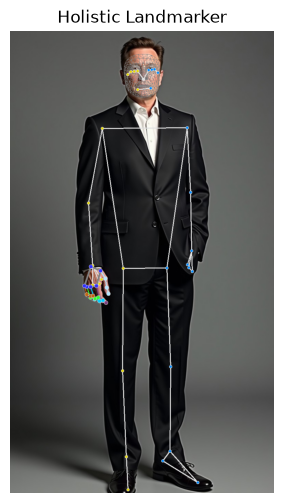

In [9]:
def draw_holistic(rgb_image, detection_result):
    annotated = np.copy(rgb_image)
    h, w = annotated.shape[:2]

    def _draw_points(landmarks, color, radius=2):
        if not landmarks:
            return
        for lm in landmarks:
            cx, cy = int(lm.x * w), int(lm.y * h)
            if 0 <= cx < w and 0 <= cy < h:
                cv2.circle(annotated, (cx, cy), radius, color, -1)

    # Face mesh
    if detection_result.face_landmarks:
        try:
            drawing_utils.draw_landmarks(
                image=annotated,
                landmark_list=detection_result.face_landmarks,  # list of landmarks
                connections=vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION,
                landmark_drawing_spec=None,
                connection_drawing_spec=drawing_styles.get_default_face_mesh_tesselation_style(),
            )
        except Exception:
            _draw_points(detection_result.face_landmarks, (200, 200, 200), 1)

    # Pose
    if detection_result.pose_landmarks:
        try:
            drawing_utils.draw_landmarks(
                image=annotated,
                landmark_list=detection_result.pose_landmarks,
                connections=vision.PoseLandmarksConnections.POSE_LANDMARKS,
                landmark_drawing_spec=drawing_styles.get_default_pose_landmarks_style(),
            )
        except Exception:
            _draw_points(detection_result.pose_landmarks, (0, 255, 0), 3)

    # Hands (left + right)
    for hand_lms in (
        detection_result.left_hand_landmarks,
        detection_result.right_hand_landmarks,
    ):
        if not hand_lms:
            continue
        try:
            drawing_utils.draw_landmarks(
                image=annotated,
                landmark_list=hand_lms,
                connections=vision.HandLandmarksConnections.HAND_CONNECTIONS,
                landmark_drawing_spec=drawing_styles.get_default_hand_landmarks_style(),
                connection_drawing_spec=drawing_styles.get_default_hand_connections_style(),
            )
        except Exception:
            _draw_points(hand_lms, (255, 0, 0), 3)

    return annotated


rgb = mp_image.numpy_view()
annotated = draw_holistic(rgb, result)
show_bgr(cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR), "Holistic Landmarker")

**Observation**

One call returns the complete body geometry students previously obtained from three separate landmarker tasks.

### Mini application: simple geometric relationship

Example: distance between left and right wrist (pose landmarks 15 and 16).

In [10]:
if result.pose_landmarks:
    pose = result.pose_landmarks  # list of 33 NormalizedLandmark
    # MediaPipe Pose indices: LEFT_WRIST=15, RIGHT_WRIST=16
    lw = pose[15]
    rw = pose[16]
    dx = lw.x - rw.x
    dy = lw.y - rw.y
    dist = (dx ** 2 + dy ** 2) ** 0.5
    print(f"Normalized wrist-to-wrist distance: {dist:.3f}")
    print(f"  left wrist:  ({lw.x:.3f}, {lw.y:.3f})")
    print(f"  right wrist: ({rw.x:.3f}, {rw.y:.3f})")
else:
    print("No pose landmarks detected.")

Normalized wrist-to-wrist distance: 0.376
  left wrist:  (0.688, 0.476)
  right wrist: (0.313, 0.508)


In [11]:
holistic.close()

## 4. Face Detector

From landmarks to detection.

```
Image
  |
Face Detector
  |
Bounding boxes + confidence
```

In [12]:
FACE_DET_MODEL = str(MODELS_DIR / "blaze_face_short_range.tflite")

base_options = python.BaseOptions(model_asset_path=FACE_DET_MODEL)
options = vision.FaceDetectorOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
)
face_detector = vision.FaceDetector.create_from_options(options)
print("Face Detector ready.")

Face Detector ready.


In [13]:


face_path = IMAGES_DIR / "face.jpg"

mp_image = mp.Image.create_from_file(str(face_path))
det_result = face_detector.detect(mp_image)

print(f"Faces detected: {len(det_result.detections)}")

Faces detected: 1


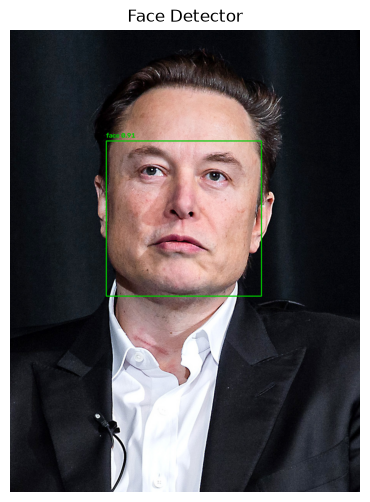

In [14]:
img = load_bgr(face_path)
h, w = img.shape[:2]

for detection in det_result.detections:
    bbox = detection.bounding_box
    x1, y1 = int(bbox.origin_x), int(bbox.origin_y)
    x2, y2 = x1 + int(bbox.width), y1 + int(bbox.height)
    score = detection.categories[0].score if detection.categories else 0.0

    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 200, 0), 2)
    label = f"face {score:.2f}"
    cv2.putText(img, label, (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 200, 0), 2)

show_bgr(img, "Face Detector")

**Observation**

Detection answers "where is the face?" with a box. Landmarks answer "where are the facial points?".

In [15]:
face_detector.close()

## 5. Gesture Recognizer

```
Image / Video
      |
Gesture Recognizer
      |
Gesture label + confidence
```

Comparison with Hand Landmarker:

| Task                | Output                    |
|---------------------|---------------------------|
| Hand Landmarker     | 21 landmarks per hand     |
| Gesture Recognizer  | Semantic gesture + score  |

In [16]:
GESTURE_MODEL = str(MODELS_DIR / "gesture_recognizer.task")

base_options = python.BaseOptions(model_asset_path=GESTURE_MODEL)
options = vision.GestureRecognizerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_hands=2,
)
gesture_recognizer = vision.GestureRecognizer.create_from_options(options)
print("Gesture Recognizer ready.")

Gesture Recognizer ready.


In [19]:
gesture_path = IMAGES_DIR / "gesture.jpg"
mp_image = mp.Image.create_from_file(str(gesture_path))   # or person_path
gesture_result = gesture_recognizer.recognize(mp_image)

print(f"Hands detected: {len(gesture_result.gestures)}")
for i, (gestures, handedness) in enumerate(zip(gesture_result.gestures, gesture_result.handedness)):
    top_gesture = gestures[0]
    hand = handedness[0]
    print(f"  Hand {i}: {hand.category_name} → {top_gesture.category_name} "
          f"({top_gesture.score:.2f})")

Hands detected: 2
  Hand 0: Left → None (0.65)
  Hand 1: Left → Open_Palm (0.72)


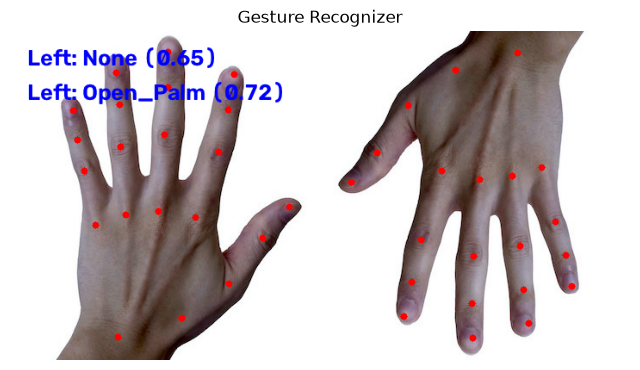

In [20]:
img = load_bgr(gesture_path)
h, w = img.shape[:2]

# Draw landmarks for every detected hand
if gesture_result.hand_landmarks:
    for hand_lms in gesture_result.hand_landmarks:
        for lm in hand_lms:
            cx, cy = int(lm.x * w), int(lm.y * h)
            cv2.circle(img, (cx, cy), 4, (0, 0, 255), -1)

# Overlay gesture labels for every hand
y_offset = 40
if gesture_result.gestures:
    for i, gestures in enumerate(gesture_result.gestures):
        if not gestures:
            continue
        top = gestures[0]                     # highest-confidence gesture for this hand
        hand_label = "Unknown"
        if gesture_result.handedness and i < len(gesture_result.handedness):
            hand_label = gesture_result.handedness[i][0].category_name  # "Left" / "Right"

        label_text = f"{hand_label}: {top.category_name} ({top.score:.2f})"
        cv2.putText(img, label_text, (20, y_offset),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)
        y_offset += 40
else:
    cv2.putText(img, "No gesture", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 0, 0), 2)

show_bgr(img, "Gesture Recognizer")

**Observation**

Hand Landmarker gives geometry. Gesture Recognizer adds a ready-made semantic label (Thumb_Up, Open_Palm, Victory, ...).

In [21]:
gesture_recognizer.close()

## 6. Image Classifier

```
Image
  |
Image Classifier
  |
Class + confidence
```

In [22]:
CLASSIFIER_MODEL = str(MODELS_DIR / "efficientnet_lite0.tflite")

base_options = python.BaseOptions(model_asset_path=CLASSIFIER_MODEL)
options = vision.ImageClassifierOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    max_results=3,
)
classifier = vision.ImageClassifier.create_from_options(options)
print("Image Classifier ready.")

Image Classifier ready.


In [26]:
obj_path = IMAGES_DIR / "objects.jpg"
mp_image = mp.Image.create_from_file(str(obj_path))
class_result = classifier.classify(mp_image)

print("Top predictions:")
for cat in class_result.classifications[0].categories:
    print(f"  {cat.category_name:25s} {cat.score:.3f}")

Top predictions:
  cheeseburger              0.889
  bagel                     0.015
  guacamole                 0.005


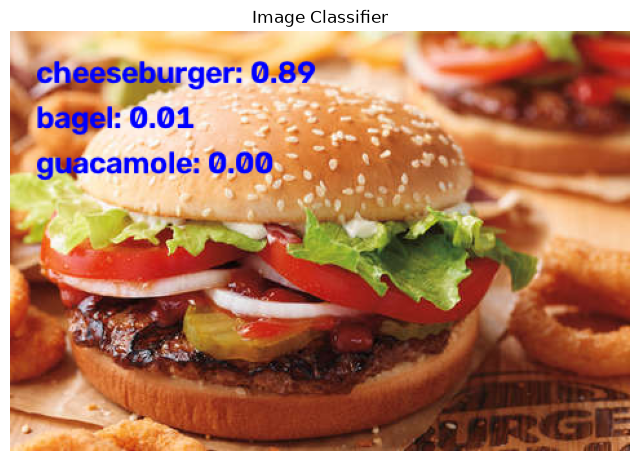

In [27]:
img = load_bgr(obj_path)
y0 = 40
for cat in class_result.classifications[0].categories:
    text = f"{cat.category_name}: {cat.score:.2f}"
    cv2.putText(img, text, (20, y0),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
    y0 += 35

show_bgr(img, "Image Classifier")

**Distinction**

```
Classification  ->  What is this image?
Detection       ->  What objects are here, and where?
```

In [28]:
classifier.close()

## 7. Object Detector

```
Image
  |
Object Detector
  |
Boxes + class labels + scores
```

In [37]:
OBJECT_MODEL = str(MODELS_DIR / "efficientdet_lite0.tflite")

base_options = python.BaseOptions(model_asset_path=OBJECT_MODEL)
options = vision.ObjectDetectorOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    score_threshold=0.2,
    max_results=6,
)
object_detector = vision.ObjectDetector.create_from_options(options)
print("Object Detector ready.")

Object Detector ready.


In [38]:
mp_image = mp.Image.create_from_file(str(obj_path))
obj_result = object_detector.detect(mp_image)

print(f"Objects detected: {len(obj_result.detections)}")
for det in obj_result.detections:
    cat = det.categories[0]
    print(f"  {cat.category_name:20s} {cat.score:.2f}")

Objects detected: 2
  sandwich             0.69
  sandwich             0.49


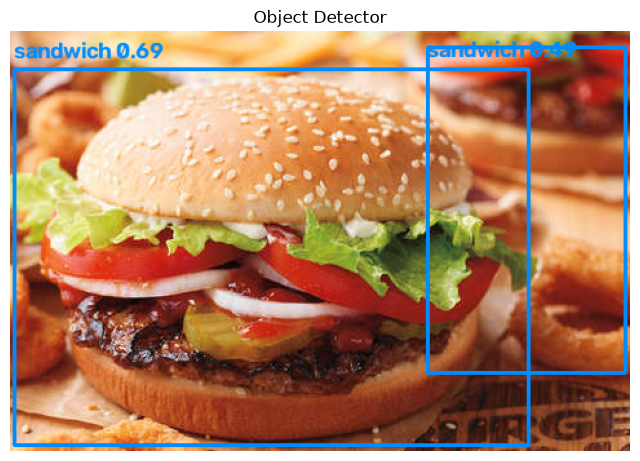

In [39]:
img = load_bgr(obj_path)

for det in obj_result.detections:
    bbox = det.bounding_box
    x1, y1 = int(bbox.origin_x), int(bbox.origin_y)
    x2 = x1 + int(bbox.width)
    y2 = y1 + int(bbox.height)
    cat = det.categories[0]
    label = f"{cat.category_name} {cat.score:.2f}"

    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 140, 0), 2)
    cv2.putText(img, label, (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 140, 0), 2)

show_bgr(img, "Object Detector")

**Observation**

Multiple objects, each with its own location and class.

In [40]:
object_detector.close()

## 8. Image Segmenter

First pixel-level output.

```
Detection
  -> "The person is here."   (bounding box)

Segmentation
  -> "These pixels belong to the person."  (mask)
```

Available MediaPipe models (among others):

- Selfie segmentation (person / background)
- Hair segmentation
- DeepLab-v3 (multi-class)

We demonstrate the Selfie model.

In [41]:
SEG_MODEL = str(MODELS_DIR / "selfie_segmenter.tflite")

base_options = python.BaseOptions(model_asset_path=SEG_MODEL)
options = vision.ImageSegmenterOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    output_category_mask=True,
)
segmenter = vision.ImageSegmenter.create_from_options(options)
print("Image Segmenter ready.")

Image Segmenter ready.


In [43]:
mp_image = mp.Image.create_from_file(str(person_path))
seg_result = segmenter.segment(mp_image)

category_mask = seg_result.category_mask.numpy_view()
print("Mask shape:", category_mask.shape)
print("Unique values:", np.unique(category_mask))

Mask shape: (1344, 768, 1)
Unique values: [  0 255]


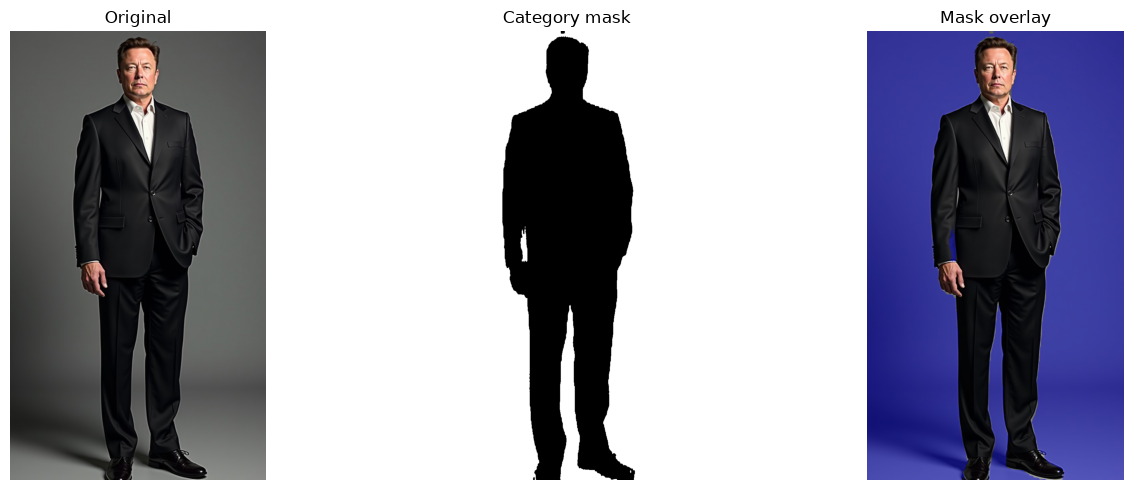

In [47]:
img = load_bgr(person_path)
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Ensure the mask is strictly 2-D
mask = (np.asarray(category_mask).squeeze() > 0).astype(np.uint8)   # shape (H, W)

# Colored overlay – two safe ways

overlay = rgb.copy()
color = np.array([0, 0, 255], dtype=np.uint8)
overlay[mask == 1] = (0.6 * overlay[mask == 1] + 0.4 * color).astype(np.uint8)


fig, axes = plt.subplots(1, 3, figsize=(14, 5))
axes[0].imshow(rgb)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Category mask")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Mask overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

**Observation**

Every pixel is assigned to a class. Bounding boxes are no longer sufficient.

In [ ]:
segmenter.close()

## 9. Final Comparison

| Task                  | Main question                                  | Output              |
|-----------------------|------------------------------------------------|---------------------|
| Hand Landmarker       | Where are the hand landmarks?                  | Landmarks           |
| Face Landmarker       | Where are the facial landmarks?                | Landmarks           |
| Pose Landmarker       | Where are the body landmarks?                  | Landmarks           |
| Holistic Landmarker   | Where are face, hands and body landmarks?      | Combined landmarks  |
| Face Detector         | Where are the faces?                           | Bounding boxes      |
| Gesture Recognizer    | What gesture is being performed?               | Gesture + score     |
| Image Classifier      | What is this image?                            | Class + score       |
| Object Detector       | What objects are present and where?            | Boxes + classes     |
| Image Segmenter       | Which pixels belong to a class / object?       | Mask                |

## 10. Final Concept

```
                Computer Vision Problem
                         |
              What information do I need?
                         |
              Choose the right representation
                         |
       +----------+----------+-------------+
       |          |          |             |
   Landmarks  Detection  Classification  Segmentation
       |          |          |             |
    Features    Boxes     Labels         Masks
```

**Takeaway**

Choose the MediaPipe task based on the information your application needs.